# Tugas Praktikum Reinforcement Learning: Perbandingan PPO vs DQN pada `LunarLander-v3`

- **Nama:** Daffa Aufa Afif
- **NRP:** 5054251022
- **Link:** https://youtu.be/rcum4_Z7OJI

---

## Ringkasan Project
Project ini mengimplementasikan dan membandingkan dua algoritma **Reinforcement Learning (RL)** populer dari library **Stable-Baselines3** pada environment simulasi fisika 2D **`LunarLander-v3`** (Gymnasium + Box2D):
1. **PPO (*Proximal Policy Optimization*)**: algoritma *Actor-Critic* (*on-policy*) yang secara eksplisit mempelajari **Policy** (Actor) dan **Value Function** (Critic).
2. **DQN (*Deep Q-Network*)**: algoritma *Value-Based* (*off-policy*) yang mempelajari **Q-Value** menggunakan *Experience Replay Buffer* dan *Target Network*.

Kedua model dilatih secara headless dengan **300.000 timesteps**


## 1. Setup Environment & Konfigurasi



In [1]:
import os
import time
import json
import glob
import warnings
from pathlib import Path

# Mode headless untuk rendering SDL/Pygame tanpa jendela GUI
os.environ["SDL_VIDEODRIVER"] = "dummy"
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio
import torch
import gymnasium as gym

from stable_baselines3 import PPO, DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.logger import configure
from stable_baselines3.common.utils import set_random_seed

# Konfigurasi global eksperimen
BASE_DIR = Path.cwd()
VIDIO_PPO_DIR = BASE_DIR / "vidio" / "ppo"
VIDIO_DQN_DIR = BASE_DIR / "vidio" / "dqn"
LOG_PPO_DIR = BASE_DIR / "logs" / "ppo"
LOG_DQN_DIR = BASE_DIR / "logs" / "dqn"
MODELS_DIR = BASE_DIR / "models"
PLOTS_DIR = BASE_DIR / "plots"

for d in [VIDIO_PPO_DIR, VIDIO_DQN_DIR, LOG_PPO_DIR, LOG_DQN_DIR, MODELS_DIR, PLOTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

ENV_ID = "LunarLander-v3"
TOTAL_TIMESTEPS = 300_000
MILESTONES = [0, 50_000, 100_000, 150_000, 200_000, 250_000, 300_000]
TRAIN_SEED = 42
VIDEO_EVAL_SEED = 42   # Seed tetap agar kondisi medan & posisi awal video landmark konsisten
N_EVAL_EPISODES = 50   # Jumlah episode evaluasi akhir

set_random_seed(TRAIN_SEED)

print(f"PyTorch           : {torch.__version__} (device: cpu, threads: {torch.get_num_threads()})")
print(f"Gymnasium         : {gym.__version__}")
print(f"Environment       : {ENV_ID}")
print(f"Total Timesteps   : {TOTAL_TIMESTEPS:,}")
print(f"Video Landmarks   : {MILESTONES}")


PyTorch           : 2.15.0+cpu (device: cpu, threads: 4)
Gymnasium         : 1.4.0
Environment       : LunarLander-v3
Total Timesteps   : 300,000
Video Landmarks   : [0, 50000, 100000, 150000, 200000, 250000, 300000]


## 2. Konsep Dasar Reinforcement Learning pada `LunarLander-v3`

Dalam Reinforcement Learning, **Agent** belajar mengambil keputusan melalui interaksi berulang dengan **Environment** tanpa data berlabel:

| Konsep RL | Implementasi |
| :--- | :--- |
| **Agent** | Model neural network **PPO** dan **DQN** yang memilih aksi pendorong roket. |
| **Environment** | Simulasi fisika 2D `LunarLander-v3` (Gymnasium + Box2D) dengan gravitasi bulan dan medan pendaratan. |
| **State ($s_t$)** | Vektor kontinu 8 dimensi: posisi $(x, y)$, kecepatan $(v_x, v_y)$, sudut $\theta$, kecepatan sudut $\omega$, serta kontak kaki kiri & kanan (biner 0/1). |
| **Action ($a_t$)** | 4 aksi diskrit: `0` = diam, `1` = nyalakan mesin kiri, `2` = nyalakan mesin utama, `3` = nyalakan mesin kanan. |
| **Reward ($r_t$)** | Positif saat mendekati landasan, melambat, kaki menyentuh tanah (+10/kaki), dan mendarat mulus (**+100**). Negatif saat menabrak (**-100**) atau memboroskan bahan bakar (-0.3/step mesin utama, -0.03/step mesin samping). Environment dianggap **solved** jika rata-rata reward $\ge 200$. |
| **Policy ($\pi$)** | Strategi pemetaan *State* $\rightarrow$ *Action*. Pada **PPO**, policy dipelajari langsung oleh jaringan *Actor* $\pi_\theta(a\|s)$. Pada **DQN**, policy dibentuk implisit dari Q-Value ($a = \arg\max_a Q(s,a)$ dengan eksplorasi $\epsilon$-greedy). |
| **Value ($V(s)$) & Q-Value ($Q(s,a)$)** | Estimasi total *discounted reward* di masa depan. **PPO** menggunakan jaringan *Critic* $V_\phi(s)$ untuk menghitung *Advantage*, sedangkan **DQN** mengestimasi $Q_\theta(s,a)$ untuk setiap pasangan state-action. |


In [2]:
# Inspeksi langsung ruang State dan Action pada LunarLander-v3
sample_env = gym.make(ENV_ID)
obs, info = sample_env.reset(seed=TRAIN_SEED)
next_obs, reward, terminated, truncated, info = sample_env.step(2)  # Aksi 2: mesin utama
sample_env.close()

print("Observation Space (State) :", sample_env.observation_space)
print("Action Space              :", sample_env.action_space)
print("Contoh State Awal (8 dim) :", np.round(obs, 4))
print("Contoh State Setelah Aksi 2:", np.round(next_obs, 4))
print(f"Contoh Reward 1 Step      : {reward:.4f}")


Observation Space (State) : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action Space              : Discrete(4)
Contoh State Awal (8 dim) : [ 0.0023  1.4181  0.2326  0.3205 -0.0027 -0.0527  0.      0.    ]
Contoh State Setelah Aksi 2: [ 0.0044  1.4259  0.2174  0.3439 -0.006  -0.0674  0.      0.    ]
Contoh Reward 1 Step      : -2.4970


## 3. Fungsi Helper: Perekaman Video Landmark & Evaluasi


In [3]:
def classify_outcome(total_reward: float, steps: int, max_steps: int = 1000) -> str:
    if total_reward >= 200:
        return "Landed (Solved >= 200)"
    elif steps >= max_steps:
        return "Timeout / Hovering"
    elif total_reward > 0:
        return "Soft / Partial Landing"
    else:
        return "Crashed"


def record_landmark_video(model, save_path: Path, milestone: int, model_name: str, seed: int = VIDEO_EVAL_SEED) -> dict:
    """Merekam 1 episode evaluasi deterministik ke format MP4."""
    env = gym.make(ENV_ID, render_mode="rgb_array")
    obs, _ = env.reset(seed=seed)
    frames = [env.render()]
    total_reward = 0.0
    steps = 0
    done = False

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(int(action))
        frames.append(env.render())
        total_reward += float(reward)
        steps += 1
        done = terminated or truncated

    env.close()
    imageio.mimsave(str(save_path), frames, fps=30, macro_block_size=16)

    outcome = classify_outcome(total_reward, steps)
    record = {
        "Model": model_name,
        "Milestone_Steps": milestone,
        "Episode_Reward": round(total_reward, 2),
        "Episode_Length": steps,
        "Outcome": outcome,
        "Video_File": str(save_path.relative_to(BASE_DIR)),
    }
    print(f"  [Video] {model_name} @ {milestone:>7,} steps -> Reward: {total_reward:>7.2f} | Steps: {steps:>4} | {outcome} | {save_path.name}")
    return record


class LandmarkVideoCallback(BaseCallback):
    """Callback SB3 untuk merekam video landmark pada setiap kelipatan timesteps tertentu."""
    def __init__(self, milestones, video_dir: Path, model_name: str, records_list: list, verbose: int = 0):
        super().__init__(verbose)
        self.milestones = sorted([m for m in milestones if m > 0])
        self.recorded = set()
        self.video_dir = video_dir
        self.model_name = model_name
        self.records_list = records_list

    def _check_and_record(self):
        for m in self.milestones:
            if m not in self.recorded and self.num_timesteps >= m:
                fname = f"{self.model_name.lower()}_step_{m:06d}.mp4"
                rec = record_landmark_video(self.model, self.video_dir / fname, m, self.model_name)
                self.records_list.append(rec)
                self.recorded.add(m)

    def _on_step(self) -> bool:
        self._check_and_record()
        return True

    def _on_training_end(self) -> None:
        # Pastikan milestone terakhir tetap terekam jika training selesai tepat di batas
        for m in self.milestones:
            if m not in self.recorded:
                fname = f"{self.model_name.lower()}_step_{m:06d}.mp4"
                rec = record_landmark_video(self.model, self.video_dir / fname, m, self.model_name)
                self.records_list.append(rec)
                self.recorded.add(m)


def evaluate_agent(model=None, n_episodes: int = N_EVAL_EPISODES, start_seed: int = 1000) -> dict:
    """Evaluasi agent (atau Random Agent jika model=None) selama n_episodes."""
    env = gym.make(ENV_ID)
    rewards, lengths = [], []

    for ep in range(n_episodes):
        obs, _ = env.reset(seed=start_seed + ep)
        ep_reward = 0.0
        ep_len = 0
        done = False
        while not done:
            if model is None:
                action = env.action_space.sample()
            else:
                action, _ = model.predict(obs, deterministic=True)
                action = int(action)
            obs, reward, terminated, truncated, _ = env.step(action)
            ep_reward += float(reward)
            ep_len += 1
            done = terminated or truncated
        rewards.append(ep_reward)
        lengths.append(ep_len)

    env.close()
    rewards = np.array(rewards)
    lengths = np.array(lengths)
    return {
        "rewards": rewards,
        "lengths": lengths,
        "mean_reward": float(np.mean(rewards)),
        "std_reward": float(np.std(rewards)),
        "min_reward": float(np.min(rewards)),
        "max_reward": float(np.max(rewards)),
        "success_rate": float(np.mean(rewards >= 200.0) * 100.0),
        "mean_length": float(np.mean(lengths)),
    }


def load_monitor_logs(log_dir: Path) -> pd.DataFrame:
    """Membaca dan menggabungkan file monitor.csv dari SB3 Monitor wrapper."""
    files = sorted(glob.glob(str(log_dir / "*monitor.csv")))
    dfs = []
    for f in files:
        df = pd.read_csv(f, skiprows=1)
        if not df.empty:
            dfs.append(df)
    if not dfs:
        return pd.DataFrame(columns=["r", "l", "t", "timesteps"])
    combined = pd.concat(dfs, ignore_index=True)
    combined = combined.sort_values("t").reset_index(drop=True)
    combined["timesteps"] = combined["l"].cumsum()
    return combined

video_records = []
print("Helper functions & LandmarkVideoCallback siap digunakan.")


Helper functions & LandmarkVideoCallback siap digunakan.


## 4. Baseline: Random Agent (Tanpa Pembelajaran)

Sebelum melatih PPO dan DQN, kita mengukur performa **Random Agent** (memilih aksi secara acak pada setiap step) selama 50 episode sebagai titik acuan (*baseline*).


In [4]:
random_eval = evaluate_agent(model=None, n_episodes=N_EVAL_EPISODES, start_seed=1000)
print("=== Evaluasi Baseline: Random Agent (50 Episode) ===")
print(f"Mean Reward  : {random_eval['mean_reward']:.2f} +/- {random_eval['std_reward']:.2f}")
print(f"Min / Max    : {random_eval['min_reward']:.2f} / {random_eval['max_reward']:.2f}")
print(f"Success Rate : {random_eval['success_rate']:.1f}% (reward >= 200)")
print(f"Avg Length   : {random_eval['mean_length']:.1f} steps/episode")


=== Evaluasi Baseline: Random Agent (50 Episode) ===
Mean Reward  : -189.00 +/- 126.71
Min / Max    : -482.18 / 60.58
Success Rate : 0.0% (reward >= 200)
Avg Length   : 123.7 steps/episode


## 5. Eksperimen 1: Training PPO (*Proximal Policy Optimization*)

**Karakteristik PPO:**
- Termasuk algoritma **On-Policy Actor-Critic**: mengumpulkan pengalaman menggunakan policy terbaru (`n_envs=4` simulasi headless paralel), menghitung *Generalized Advantage Estimation (GAE)* menggunakan jaringan **Value (Critic)**, lalu memperbarui jaringan **Policy (Actor)** dengan mekanisme *clipped surrogate objective* agar pembaruan tetap stabil.
- Menggunakan konfigurasi hyperparameter yang teruji untuk `LunarLander-v3` (`n_steps=1024`, `batch_size=64`, `n_epochs=4`, `gamma=0.999`, `gae_lambda=0.98`, `ent_coef=0.01`).


In [5]:
# Bersihkan log PPO sebelumnya jika notebook dijalankan ulang
for old_f in LOG_PPO_DIR.glob("*"):
    old_f.unlink()

ppo_env = make_vec_env(
    ENV_ID,
    n_envs=4,
    seed=TRAIN_SEED,
    monitor_dir=str(LOG_PPO_DIR),
)

ppo_model = PPO(
    policy="MlpPolicy",
    env=ppo_env,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    n_epochs=4,
    gamma=0.999,
    gae_lambda=0.98,
    ent_coef=0.01,
    seed=TRAIN_SEED,
    device="cpu",
    verbose=0,
)
ppo_model.set_logger(configure(str(LOG_PPO_DIR), ["csv"]))

print("=== Memulai Training PPO (300.000 Timesteps) ===")
# Rekam video landmark step 0 (sebelum training)
video_records.append(
    record_landmark_video(ppo_model, VIDIO_PPO_DIR / "ppo_step_000000.mp4", 0, "PPO")
)

ppo_callback = LandmarkVideoCallback(MILESTONES, VIDIO_PPO_DIR, "PPO", video_records)
t0 = time.time()
ppo_model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=ppo_callback, progress_bar=False)
ppo_train_time = time.time() - t0

ppo_model_path = MODELS_DIR / "ppo_lunarlander_300k"
ppo_model.save(str(ppo_model_path))
ppo_env.close()

ppo_monitor = load_monitor_logs(LOG_PPO_DIR)
print(f"\nTraining PPO selesai dalam {ppo_train_time:.1f} detik ({ppo_train_time/60:.2f} menit)")
print(f"Total Episode PPO tercatat : {len(ppo_monitor)} episode")
print(f"Model tersimpan di         : {ppo_model_path}.zip")


=== Memulai Training PPO (300.000 Timesteps) ===


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] PPO @       0 steps -> Reward: -824.83 | Steps:  121 | Crashed | ppo_step_000000.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] PPO @  50,000 steps -> Reward: -293.19 | Steps:  243 | Crashed | ppo_step_050000.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


... (6 outputs left out)

  [Video] PPO @ 250,000 steps -> Reward:  148.03 | Steps:  835 | Soft / Partial Landing | ppo_step_250000.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] PPO @ 300,000 steps -> Reward:  203.54 | Steps:  558 | Landed (Solved >= 200) | ppo_step_300000.mp4



Training PPO selesai dalam 347.2 detik (5.79 menit)
Total Episode PPO tercatat : 997 episode
Model tersimpan di         : /media/dff/Elements1/ITS_semester3/ML/Tugas/RL/prk/models/ppo_lunarlander_300k.zip


## 6. Eksperimen 2: Training DQN (*Deep Q-Network*)

**Karakteristik DQN:**
- Termasuk algoritma **Off-Policy Value-Based**: menyimpan transisi $(s, a, r, s', done)$ ke dalam **Replay Buffer** (kapasitas 50.000) dan melatih jaringan **Q-Network** (`net_arch=[256, 256]`) untuk memprediksi **Q-Value** $Q(s,a)$ menggunakan persamaan Bellman dengan bantuan **Target Network**.
- Strategi eksplorasi menggunakan **$\epsilon$-greedy**: dimulai dari $\epsilon = 1.0$ (eksplorasi penuh) lalu turun linear ke $\epsilon = 0.05$ pada 15% awal training.


In [6]:
# Bersihkan log DQN sebelumnya jika notebook dijalankan ulang
for old_f in LOG_DQN_DIR.glob("*"):
    old_f.unlink()

dqn_env = Monitor(gym.make(ENV_ID), filename=str(LOG_DQN_DIR / "monitor.csv"))
dqn_env.reset(seed=TRAIN_SEED)

dqn_model = DQN(
    policy="MlpPolicy",
    env=dqn_env,
    learning_rate=6.3e-4,
    buffer_size=50_000,
    learning_starts=1_000,
    batch_size=128,
    gamma=0.99,
    train_freq=4,
    gradient_steps=2,
    target_update_interval=250,
    exploration_fraction=0.15,
    exploration_final_eps=0.05,
    policy_kwargs=dict(net_arch=[256, 256]),
    seed=TRAIN_SEED,
    device="cpu",
    verbose=0,
)
dqn_model.set_logger(configure(str(LOG_DQN_DIR), ["csv"]))

print("=== Memulai Training DQN (300.000 Timesteps) ===")
# Rekam video landmark step 0 (sebelum training)
video_records.append(
    record_landmark_video(dqn_model, VIDIO_DQN_DIR / "dqn_step_000000.mp4", 0, "DQN")
)

dqn_callback = LandmarkVideoCallback(MILESTONES, VIDIO_DQN_DIR, "DQN", video_records)
t0 = time.time()
dqn_model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=dqn_callback, progress_bar=False)
dqn_train_time = time.time() - t0

dqn_model_path = MODELS_DIR / "dqn_lunarlander_300k"
dqn_model.save(str(dqn_model_path))
dqn_env.close()

dqn_monitor = load_monitor_logs(LOG_DQN_DIR)
print(f"\nTraining DQN selesai dalam {dqn_train_time:.1f} detik ({dqn_train_time/60:.2f} menit)")
print(f"Total Episode DQN tercatat : {len(dqn_monitor)} episode")
print(f"Model tersimpan di         : {dqn_model_path}.zip")


=== Memulai Training DQN (300.000 Timesteps) ===


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] DQN @       0 steps -> Reward: -822.59 | Steps:   80 | Crashed | dqn_step_000000.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] DQN @  50,000 steps -> Reward:  -38.97 | Steps: 1000 | Timeout / Hovering | dqn_step_050000.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


... (5 outputs left out)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] DQN @ 250,000 steps -> Reward:  272.98 | Steps:  217 | Landed (Solved >= 200) | dqn_step_250000.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  [Video] DQN @ 300,000 steps -> Reward:  268.95 | Steps:  231 | Landed (Solved >= 200) | dqn_step_300000.mp4

Training DQN selesai dalam 535.5 detik (8.92 menit)
Total Episode DQN tercatat : 940 episode
Model tersimpan di         : /media/dff/Elements1/ITS_semester3/ML/Tugas/RL/prk/models/dqn_lunarlander_300k.zip


## 7. Evaluasi Strategi Agent & Ringkasan Video Landmark

Kita mengevaluasi ketiga agent (**Random**, **PPO**, dan **DQN**) pada **50 episode uji identik** (`seed = 1000..1049`) dengan mode deterministik (`deterministic=True`) agar perbandingan performa akhir objektif.


In [7]:
ppo_eval = evaluate_agent(model=ppo_model, n_episodes=N_EVAL_EPISODES, start_seed=1000)
dqn_eval = evaluate_agent(model=dqn_model, n_episodes=N_EVAL_EPISODES, start_seed=1000)

eval_summary_df = pd.DataFrame([
    {
        "Model": "Random Agent (Baseline)",
        "Mean Reward": round(random_eval["mean_reward"], 2),
        "Std Reward": round(random_eval["std_reward"], 2),
        "Min Reward": round(random_eval["min_reward"], 2),
        "Max Reward": round(random_eval["max_reward"], 2),
        "Success Rate (>=200) %": round(random_eval["success_rate"], 1),
        "Avg Eval Ep Length": round(random_eval["mean_length"], 1),
        "Train Episodes": 0,
        "Train Time (s)": 0.0,
    },
    {
        "Model": "PPO (300k steps)",
        "Mean Reward": round(ppo_eval["mean_reward"], 2),
        "Std Reward": round(ppo_eval["std_reward"], 2),
        "Min Reward": round(ppo_eval["min_reward"], 2),
        "Max Reward": round(ppo_eval["max_reward"], 2),
        "Success Rate (>=200) %": round(ppo_eval["success_rate"], 1),
        "Avg Eval Ep Length": round(ppo_eval["mean_length"], 1),
        "Train Episodes": len(ppo_monitor),
        "Train Time (s)": round(ppo_train_time, 1),
    },
    {
        "Model": "DQN (300k steps)",
        "Mean Reward": round(dqn_eval["mean_reward"], 2),
        "Std Reward": round(dqn_eval["std_reward"], 2),
        "Min Reward": round(dqn_eval["min_reward"], 2),
        "Max Reward": round(dqn_eval["max_reward"], 2),
        "Success Rate (>=200) %": round(dqn_eval["success_rate"], 1),
        "Avg Eval Ep Length": round(dqn_eval["mean_length"], 1),
        "Train Episodes": len(dqn_monitor),
        "Train Time (s)": round(dqn_train_time, 1),
    },
])

eval_summary_df.to_csv(BASE_DIR / "logs" / "evaluation_summary.csv", index=False)
print("=== Tabel Perbandingan Evaluasi Akhir (50 Episode) ===")
display(eval_summary_df)

video_df = pd.DataFrame(video_records)
video_df.to_csv(BASE_DIR / "logs" / "video_landmarks_summary.csv", index=False)
print("\n=== Ringkasan Video Landmark (Kelipatan 50k Steps) ===")
display(video_df)


=== Tabel Perbandingan Evaluasi Akhir (50 Episode) ===


,Model,Mean Reward,Std Reward,Min Reward,Max Reward,Success Rate (>=200) %,Avg Eval Ep Length,Train Episodes,Train Time (s)
0,Random Agent (Baseline),-189.00,126.71,-482.18,60.58,0.0,123.7,0,0.0
1,PPO (300k steps),189.95,48.35,-32.96,267.17,38.0,635.1,997,347.2
2,DQN (300k steps),242.32,71.63,20.62,321.01,78.0,362.5,940,535.5



=== Ringkasan Video Landmark (Kelipatan 50k Steps) ===


,Model,Milestone_Steps,Episode_Reward,Episode_Length,Outcome,Video_File
0,PPO,0,-824.83,121,Crashed,vidio/ppo/ppo_step_000000.mp4
1,PPO,50000,-293.19,243,Crashed,vidio/ppo/ppo_step_050000.mp4
2,PPO,100000,-243.58,938,Crashed,vidio/ppo/ppo_step_100000.mp4
3,PPO,150000,-729.88,1000,Timeout / Hovering,vidio/ppo/ppo_step_150000.mp4
4,PPO,200000,-64.03,1000,Timeout / Hovering,vidio/ppo/ppo_step_200000.mp4
5,PPO,250000,148.03,835,Soft / Partial Landing,vidio/ppo/ppo_step_250000.mp4
6,PPO,300000,203.54,558,Landed (Solved >= 200),vidio/ppo/ppo_step_300000.mp4
7,DQN,0,-822.59,80,Crashed,vidio/dqn/dqn_step_000000.mp4
8,DQN,50000,-38.97,1000,Timeout / Hovering,vidio/dqn/dqn_step_050000.mp4
9,DQN,100000,-7.21,1000,Timeout / Hovering,vidio/dqn/dqn_step_100000.mp4


## 8. Visualisasi Kurva Pembelajaran, Metrik Internal (Policy & Value), dan Distribusi Evaluasi

Grafik berikut memvisualisasikan:
1. **Kurva Learning (*Episode Reward vs Timesteps*):** menunjukkan proses pembelajaran agent dari awal hingga 300.000 timesteps.
2. **Metrik Internal Training:** memperlihatkan dinamika perubahan **Value Loss** & **Policy Gradient Loss** pada PPO, serta **TD/Q-Value Loss** & **Exploration Rate ($\epsilon$)** pada DQN.
3. **Perbandingan Evaluasi Akhir:** membandingkan *Mean Reward* dan sebaran skor 50 episode uji antara Random Agent, PPO, dan DQN.


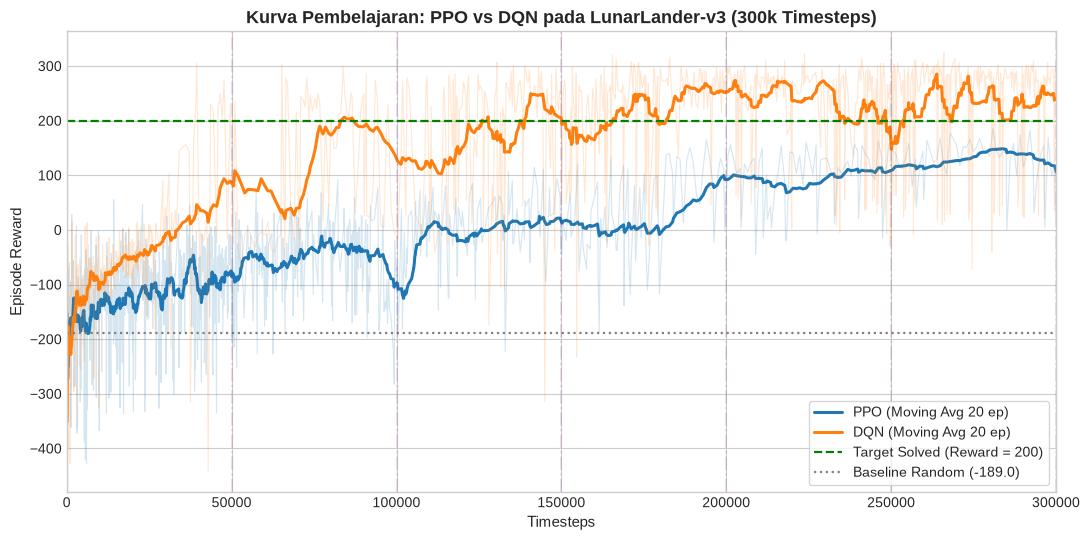

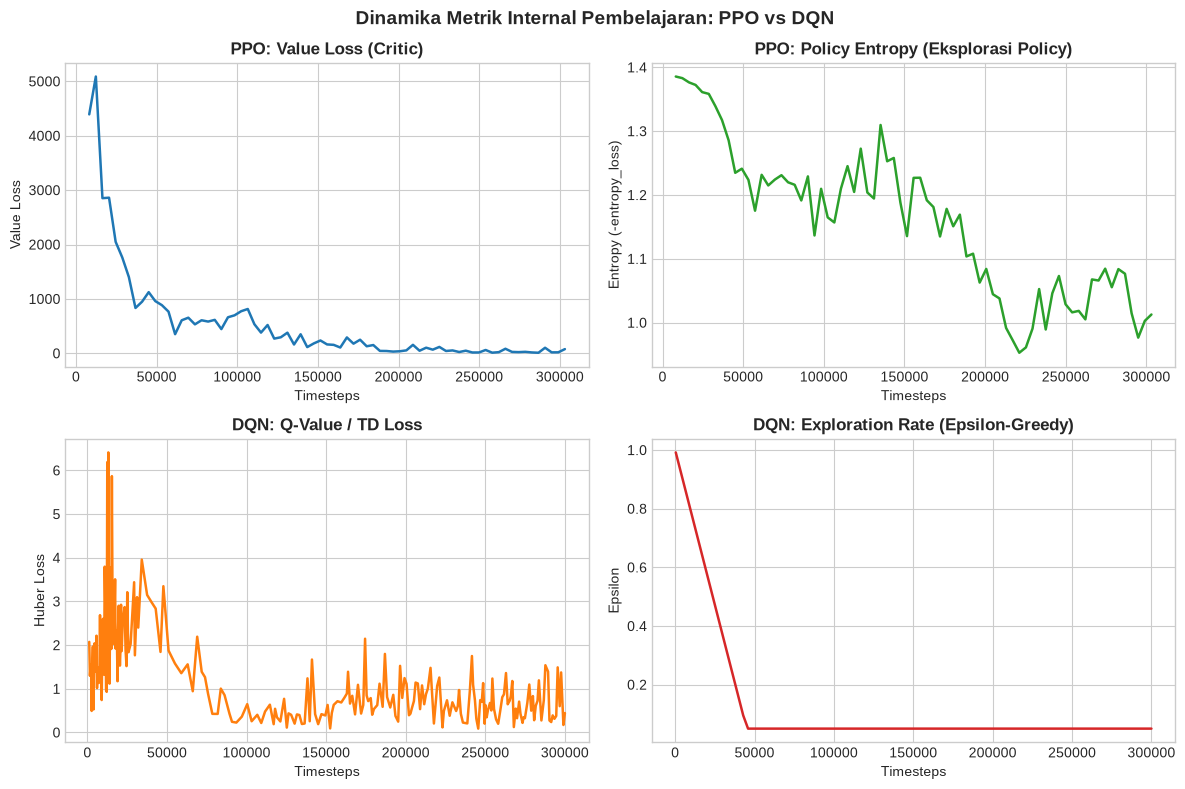

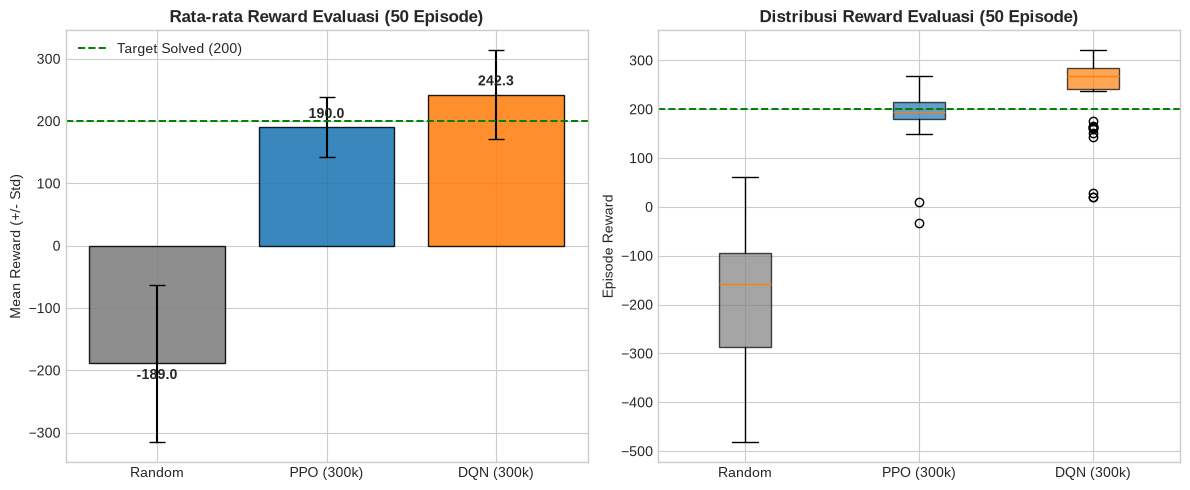

In [8]:
plt.style.use("seaborn-v0_8-whitegrid")

# --- Plot 1: Learning Curve Comparison ---
fig, ax = plt.subplots(figsize=(11, 5.5))

if not ppo_monitor.empty:
    ppo_roll = ppo_monitor["r"].rolling(window=20, min_periods=1).mean()
    ax.plot(ppo_monitor["timesteps"], ppo_monitor["r"], color="#1f77b4", alpha=0.18, linewidth=0.8)
    ax.plot(ppo_monitor["timesteps"], ppo_roll, color="#1f77b4", linewidth=2.2, label="PPO (Moving Avg 20 ep)")

if not dqn_monitor.empty:
    dqn_roll = dqn_monitor["r"].rolling(window=20, min_periods=1).mean()
    ax.plot(dqn_monitor["timesteps"], dqn_monitor["r"], color="#ff7f0e", alpha=0.18, linewidth=0.8)
    ax.plot(dqn_monitor["timesteps"], dqn_roll, color="#ff7f0e", linewidth=2.2, label="DQN (Moving Avg 20 ep)")

ax.axhline(200, color="green", linestyle="--", linewidth=1.6, label="Target Solved (Reward = 200)")
ax.axhline(random_eval["mean_reward"], color="gray", linestyle=":", linewidth=1.6, label=f"Baseline Random ({random_eval['mean_reward']:.1f})")

for m in MILESTONES[1:]:
    ax.axvline(m, color="purple", alpha=0.12, linestyle="-.")

ax.set_title("Kurva Pembelajaran: PPO vs DQN pada LunarLander-v3 (300k Timesteps)", fontsize=13, fontweight="bold")
ax.set_xlabel("Timesteps", fontsize=11)
ax.set_ylabel("Episode Reward", fontsize=11)
ax.set_xlim(0, TOTAL_TIMESTEPS)
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "learning_curve_comparison.png", dpi=150)
plt.show()

# --- Plot 2: Internal Metrics (Value Loss, Policy Loss, Q-Loss, Epsilon) ---
ppo_prog = pd.read_csv(LOG_PPO_DIR / "progress.csv")
dqn_prog = pd.read_csv(LOG_DQN_DIR / "progress.csv")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# PPO Value Loss
if "train/value_loss" in ppo_prog.columns:
    sub = ppo_prog.dropna(subset=["train/value_loss", "time/total_timesteps"])
    axes[0, 0].plot(sub["time/total_timesteps"], sub["train/value_loss"], color="#1f77b4", linewidth=1.8)
axes[0, 0].set_title("PPO: Value Loss (Critic)", fontweight="bold")
axes[0, 0].set_xlabel("Timesteps")
axes[0, 0].set_ylabel("Value Loss")

# PPO Policy Gradient Loss & Entropy
if "train/entropy_loss" in ppo_prog.columns:
    sub = ppo_prog.dropna(subset=["train/entropy_loss", "time/total_timesteps"])
    axes[0, 1].plot(sub["time/total_timesteps"], -sub["train/entropy_loss"], color="#2ca02c", linewidth=1.8)
axes[0, 1].set_title("PPO: Policy Entropy (Eksplorasi Policy)", fontweight="bold")
axes[0, 1].set_xlabel("Timesteps")
axes[0, 1].set_ylabel("Entropy (-entropy_loss)")

# DQN TD / Q-Value Loss
if "train/loss" in dqn_prog.columns:
    sub = dqn_prog.dropna(subset=["train/loss", "time/total_timesteps"])
    axes[1, 0].plot(sub["time/total_timesteps"], sub["train/loss"], color="#ff7f0e", linewidth=1.8)
axes[1, 0].set_title("DQN: Q-Value / TD Loss", fontweight="bold")
axes[1, 0].set_xlabel("Timesteps")
axes[1, 0].set_ylabel("Huber Loss")

# DQN Exploration Rate (Epsilon)
if "rollout/exploration_rate" in dqn_prog.columns:
    sub = dqn_prog.dropna(subset=["rollout/exploration_rate", "time/total_timesteps"])
    axes[1, 1].plot(sub["time/total_timesteps"], sub["rollout/exploration_rate"], color="#d62728", linewidth=1.8)
axes[1, 1].set_title("DQN: Exploration Rate (Epsilon-Greedy)", fontweight="bold")
axes[1, 1].set_xlabel("Timesteps")
axes[1, 1].set_ylabel("Epsilon")

plt.suptitle("Dinamika Metrik Internal Pembelajaran: PPO vs DQN", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "internal_metrics_ppo_dqn.png", dpi=150)
plt.show()

# --- Plot 3: Final Evaluation Comparison ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ["Random", "PPO (300k)", "DQN (300k)"]
means = [random_eval["mean_reward"], ppo_eval["mean_reward"], dqn_eval["mean_reward"]]
stds = [random_eval["std_reward"], ppo_eval["std_reward"], dqn_eval["std_reward"]]
colors = ["#7f7f7f", "#1f77b4", "#ff7f0e"]

bars = axes[0].bar(labels, means, yerr=stds, capsize=6, color=colors, alpha=0.88, edgecolor="black")
axes[0].axhline(200, color="green", linestyle="--", linewidth=1.4, label="Target Solved (200)")
axes[0].set_title("Rata-rata Reward Evaluasi (50 Episode)", fontweight="bold")
axes[0].set_ylabel("Mean Reward (+/- Std)")
axes[0].legend()
for bar, val in zip(bars, means):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + (15 if val >= 0 else -25), f"{val:.1f}", ha="center", fontweight="bold")

bp = axes[1].boxplot(
    [random_eval["rewards"], ppo_eval["rewards"], dqn_eval["rewards"]],
    tick_labels=labels,
    patch_artist=True,
)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
axes[1].axhline(200, color="green", linestyle="--", linewidth=1.4)
axes[1].set_title("Distribusi Reward Evaluasi (50 Episode)", fontweight="bold")
axes[1].set_ylabel("Episode Reward")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "evaluation_comparison.png", dpi=150)
plt.show()


## 9. Analisis & Kesimpulan

### A. Analisis Hasil Eksperimen

1. **Bukti Pembelajaran (Baseline vs Trained Agents):**
   - **Random Agent** menghasilkan rata-rata reward **-189.00 ± 126.71** dengan **0.0% success rate** dan rata-rata panjang episode hanya **123.7 steps** karena pesawat hampir selalu langsung jatuh/menabrak.
   - Setelah dilatih selama **300.000 timesteps**, baik **PPO** (**189.95 ± 48.35**) maupun **DQN** (**242.32 ± 71.63**) mengalami peningkatan performa yang sangat drastis dibanding baseline acak.

2. **Perbandingan Sample Efficiency & Kualitas Pendaratan (DQN Unggul di 300k Steps):**
   - **DQN** berhasil melampaui ambang *solved* (`>= 200`) secara meyakinkan dengan *Mean Reward* **242.32**, *Success Rate* **78.0%**, dan skor minimum **+20.62** (tidak mengalami crash fatal pada 50 episode uji).
   - Keunggulan *sample efficiency* DQN terlihat jelas pada progres **video landmark** (`seed=42`): sejak **50k steps** DQN sudah mampu menahan jatuh (hovering), dan pada **200k steps** sudah sukses mendarat (**+240.88** dalam 381 steps) lalu makin efisien di **250k–300k steps** (**+272.98** / **+268.95** hanya dalam ~217–231 steps). Hal ini terjadi karena DQN bersifat **off-policy** dengan *Replay Buffer*, sehingga setiap pengalaman interaksi bisa dipakai melatih Q-Network secara berulang-ulang.
   - **PPO** bersifat **on-policy** (pengalaman rollout hanya dipakai beberapa epoch lalu dibuang), sehingga pada budget 300k steps baru mencapai tahap awal konvergensi: *Mean Reward* **189.95** (sangat dekat dengan 200), *Success Rate* **38.0%**, dan rata-rata durasi episode masih cukup panjang (**635.1 steps**) karena cenderung hati-hati/melayang cukup lama sebelum mendarat. Pada video landmark `seed=42`, PPO baru berhasil mendarat sukses tepat di **300k steps** (**+203.54**, 558 steps).

3. **Perbandingan Kestabilan & Efisiensi Komputasi (PPO Lebih Cepat & Lebih Rendah Variansinya):**
   - **Waktu Training:** PPO selesai dalam **347.2 detik (~5.8 menit)** dengan `n_envs=4` paralel, sekitar **1.54x lebih cepat** dibanding DQN (**535.5 detik / ~8.9 menit**) yang melakukan update gradient lebih intensif.
   - **Kestabilan:** PPO memiliki standar deviasi reward evaluasi lebih kecil (**48.35**) dibandingkan DQN (**71.63**), mencerminkan efek *clipped surrogate objective* pada PPO yang menjaga pembaruan policy tetap stabil.
   - **Jumlah Episode Training:** Dalam budget 300.000 timesteps yang sama, PPO menjalani **997 episode** sedangkan DQN **940 episode**. DQN memiliki episode sedikit lebih sedikit karena sejak awal (50k–150k) lebih cepat memasuki fase *hovering* berdurasi 1.000 steps per episode.

---

### B. Kesimpulan

1. Seluruh konsep inti Reinforcement Learning (**Agent, Environment, State, Action, Reward, Policy, Value/Q-Value**) berhasil diterapkan dan dibuktikan melalui interaksi mandiri agent pada `LunarLander-v3`.
2. Pada budget **300.000 timesteps**, **DQN lebih unggul dalam performa akhir dan *sample efficiency*** (*Mean Reward* **242.32**, *Success Rate* **78.0%**, mendarat lebih cepat dengan rata-rata **362.5 steps**), sehingga berhasil menuntaskan (*solve*) `LunarLander-v3`.
3. **PPO lebih unggul dalam kecepatan komputasi di CPU** (**347.2 detik** vs **535.5 detik**) dan memiliki variansi evaluasi yang lebih kecil (**±48.35**), meskipun sebagai algoritma *on-policy* membutuhkan budget timesteps sedikit lebih besar (misalnya 500k steps) untuk menyamai *success rate* DQN.



## 10. Referensi / Sumber

1. **Gymnasium Documentation — LunarLander-v3:** https://gymnasium.farama.org/environments/box2d/lunar_lander/
2. **Stable-Baselines3 Documentation (PPO & DQN):** https://stable-baselines3.readthedocs.io/
3. **RL Baselines3 Zoo (Referensi Hyperparameter LunarLander):** https://github.com/DLR-RM/rl-baselines3-zoo

